# Arrays 51801495 and 51815311 — can the standing cell be made simpler?

Under the brief of **2026-11-10** the objective is the **smallest or most
analytically tractable** architecture that still learns direct deduction, not a
stronger solver and not the fewest parameters. The standing cell is **J2,
`no_mlp L=16 d192`, 2,504,890 trainable, `rho_50` 0.580** (finding 53): sixteen
distinct attention-only layers, composed.

There are exactly two ways to make that simpler, and these two stages are one
each.

| stage | cell | route | trainable |
|---|---|---|---|
| **O** | `no_mlp L=16 d176` (**OA**) | smaller at the same arrangement | 2,115,930 |
| **P** | `tied_no_mlp T=16 d192` (**P1**) | same size, **one** block applied 16 times | 270,010 |

Stage O's cell was placed inside the **measured gap**: sorted by trainable count
every attention-only N=48 rung falls into two flat groups with one step between
them — 1.15M/1.35M/1.76M/1.91M at 0.761/0.773/0.757/0.754, all past the free
line, and 2.50M/2.57M at 0.580/0.579, both free. OA at 2,115,930 is strictly
between H2 (1,908,922, past) and J2 (2,504,890, free).

Stage P's cell shares **one** block across all sixteen applications, so the
network is literally `h_{t+1} = F(h_t)`. Direct deduction proceeds in
synchronous rounds, so if a tied cell learns it, *"one layer = one deduction
round"* stops being an interpretation and becomes structural — and a theory has
**one** operator to analyze instead of sixteen.

**Both answers are negative, and they are negative in different ways.** That is
why there is one deck for the two stages rather than two decks.

In [1]:
import os, subprocess, sys
sys.path.insert(0, "/home/users/hshunt/spin_gnn")
sys.path.insert(0, "/home/users/hshunt/.local/lib/claude-slides")
os.chdir("/home/users/hshunt/spin_gnn")

print("commit  ", subprocess.run(["git", "rev-parse", "HEAD"],
                                 capture_output=True, text=True).stdout.strip())
print("branch  ", subprocess.run(["git", "rev-parse", "--abbrev-ref", "HEAD"],
                                 capture_output=True, text=True).stdout.strip())
print("stage O ", "array 51801495 (3 of 6 COMPLETED, 3 CANCELLED) -> scorer 51801620")
print("stage P ", "array 51815311 (3 of 3 COMPLETED)              -> scorer 51815318")
print("stage S ", "array 51853969 RUNNING -- P1's registered follow-up")

commit   dad892983694497fb096b5d2f41aba0b3538dce2
branch   sudoku-dd
stage O  array 51801495 (3 of 6 COMPLETED, 3 CANCELLED) -> scorer 51801620
stage P  array 51815311 (3 of 3 COMPLETED)              -> scorer 51815318
stage S  array 51853969 RUNNING -- P1's registered follow-up


## 1. The cells, field by field

The claim that these differ from J2 in **exactly** the one intended axis each is
checked against every `config.json` rather than asserted. Anything that is not
`n_nodes=48`, `degree=5`, `n_colors=4`, `shuffle_adj=True`, `fall=True`,
240k × 50 epochs, `nhead=4`, `dim_feedforward=1024`, no warmup is a different
experiment wearing the same name.

`arch_mode` is the field that separates P1 from J2: they share `num_layers=16`
and `d_model=192` exactly, and only `tied_no_mlp` vs `no_mlp` tells them
apart.

In [2]:
import json
from notebooks.make_stageop_deck import KEYS, load_stageop

FIXED = dict(n_nodes=48, degree=5, n_colors=4, shuffle_adj=True, fall=True,
             nhead=4, dim_feedforward=1024, epochs=50, n_train_instances=240000)
S = load_stageop(boot=200)
rows, bad = [], 0
for tag in ("OA", "P1", "J2", "H2"):
    for m in sorted(S["ms"][tag] or [], key=lambda m: m["seed"]):
        c = json.load(open(os.path.join(m["path"], "config.json")))
        off = [k for k, v in FIXED.items() if c.get(k) != v]
        bad += bool(off)
        rows.append((tag, (c.get("arch_mode") or "full"), c["num_layers"],
                     c["d_model"], c["seed"], off))
for tag, arch, L, dm, seed, off in rows:
    print("  %-3s %-13s L=%-2d d=%-3d s%d   %s"
          % (tag, arch, L, dm, seed, "ok" if not off else "DIFFERS: %s" % off))
print()
print("%d cells, %d differing from the registered budget" % (len(rows), bad))
assert bad == 0, "a cell differs from the registered budget in more than arch/shape"
assert len(rows) == 12, "expected 12 cells (4 rungs x 3 seeds), got %d" % len(rows)

  OA  no_mlp        L=16 d=176 s0   ok
  OA  no_mlp        L=16 d=176 s1   ok
  OA  no_mlp        L=16 d=176 s2   ok
  P1  tied_no_mlp   L=16 d=192 s0   ok
  P1  tied_no_mlp   L=16 d=192 s1   ok
  P1  tied_no_mlp   L=16 d=192 s2   ok
  J2  no_mlp        L=16 d=192 s0   ok
  J2  no_mlp        L=16 d=192 s1   ok
  J2  no_mlp        L=16 d=192 s2   ok
  H2  no_mlp        L=12 d=192 s0   ok
  H2  no_mlp        L=12 d=192 s1   ok
  H2  no_mlp        L=12 d=192 s2   ok

12 cells, 0 differing from the registered budget


## 2. The trainable counts are the formula, not a hope

`(630*d + 58) + (4*d^2 + 8*d)*L` for an untied attention-only cell. **A tied cell
pays the per-block term exactly once**, however many times the block is applied —
that single `*1` instead of `*16` is the whole 9.28× difference between P1 and
J2, and it is checked against the count the checkpoint reports.

In [3]:
def untied(d, L): return (630 * d + 58) + (4 * d * d + 8 * d) * L
def tied(d):       return (630 * d + 58) + (4 * d * d + 8 * d)

for tag, want in (("OA", untied(176, 16)), ("J2", untied(192, 16)),
                  ("H2", untied(192, 12)), ("P1", tied(192))):
    got = S["got"][tag]["trainable"]
    print("  %-3s disk %9s   formula %9s   %s"
          % (tag, "{:,}".format(got), "{:,}".format(want),
             "ok" if got == want else "MISMATCH"))
    assert got == want, tag
print()
print("  P1 / J2 = %.2fx fewer trainable parameters at the SAME depth and width"
      % (S["got"]["J2"]["trainable"] / S["got"]["P1"]["trainable"]))

  OA  disk 2,115,930   formula 2,115,930   ok
  J2  disk 2,504,890   formula 2,504,890   ok
  H2  disk 1,908,922   formula 1,908,922   ok
  P1  disk   270,010   formula   270,010   ok

  P1 / J2 = 9.28x fewer trainable parameters at the SAME depth and width


## 3. The two registered scorers are the authority

Run as subprocesses so that what appears below is literally what
`scripts/stageo_score.py` and `scripts/stagep_score.py` print — the same text
jobs `51801620` and `51815318` produced. No verdict in this notebook is computed
a second time in prose.

Each scorer re-reads its own control from disk (stage O: the four bracketing
rungs; stage P: the untied twin) and **exits non-zero** if a frozen literal has
drifted, which is why both were committed before their arrays could start.

In [4]:
for mod in ("scripts.stageo_score", "scripts.stagep_score"):
    out = subprocess.run([sys.executable, "-u", "-m", mod],
                         capture_output=True, text=True)
    print("=" * 72)
    print("%s   rc=%d" % (mod, out.returncode))
    print("=" * 72)
    print(out.stdout)
    if out.stderr.strip():
        print("STDERR:", out.stderr[-2000:])

scripts.stageo_score   rc=0
STAGE O -- size or shape? matched-size rungs inside the measured gap
  scanning: /scratch/users/hshunt/spin_gnn/sudoku_n48_sizeshape_O_2026-11-10 /scratch/users/hshunt/spin_gnn/sudoku_n48_minarch_H_2026-11-05 /scratch/users/hshunt/spin_gnn/sudoku_n48_minarch_I_2026-11-05 /scratch/users/hshunt/spin_gnn/sudoku_n48_minarch_J_2026-11-05 /scratch/users/hshunt/spin_gnn/sudoku_n48_minarch_K_2026-11-09 /scratch/users/hshunt/spin_gnn/sudoku_n48_minarch_2026-11-04 /scratch/users/hshunt/spin_gnn/sudoku_n48_minarch_L6_2026-11-04 /scratch/users/hshunt/spin_gnn/sudoku_n48_minarch_C_2026-11-04 /scratch/users/hshunt/spin_gnn/sudoku_n48_minarch_D_2026-11-04
  bars (N=48, reused not refrozen): s* 0.1484 rho_50 / 0.2918 mean_solve, free 0.74, plateau 1.64, LOO 0.0423
  stage M's N=96 bars are a different size and appear nowhere below.
  the gap under test: (1,908,922, 2,504,890) trainable

=== CONTROL -- the bracketing rungs, re-read from disk ============
  KA  L=16 d160  rho

## 4. Stage O: a real level, one thousandth past the line

OA returns a **measured** `rho_50` on every seed — 0.734 / 0.745 / 0.741, three
of three crossing 0.5 on a grid whose floor is 0.33 — and all three escape the
1.64 plateau. The median, **0.741**, misses the free line (`≤ 0.740`) by 0.001,
which is under `0.01 s*` and an order of magnitude smaller than the cell's own
seed span (0.734–0.745).

That is a *near miss on the gate*, not a near miss on the standing minimum:
J2 sits at 0.580, and nothing in the 1.91M–2.50M range comes near it.

  OA median rho_50 0.741   free line 0.740   miss +0.001
  seeds 0.734 / 0.745 / 0.741


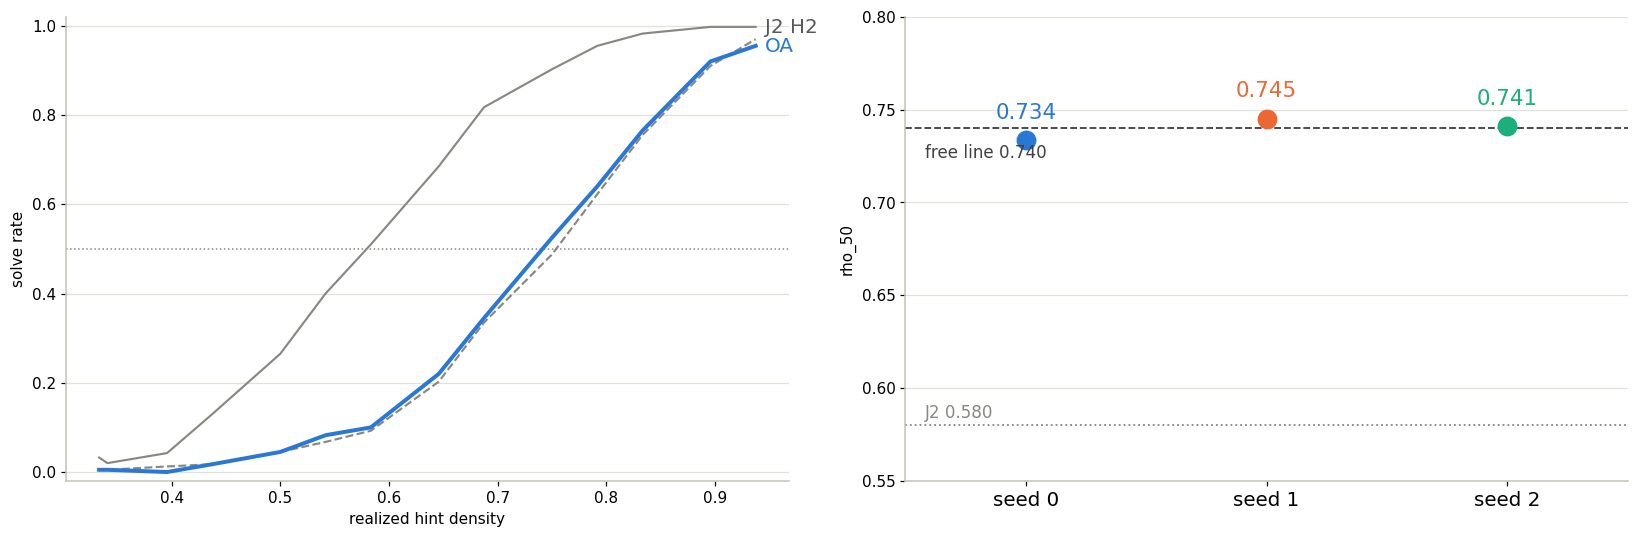

In [5]:
import matplotlib.pyplot as plt
from notebooks.make_stageop_deck import draw_bracket, draw_per_seed
from scripts.stagek_score import FREE
from scripts.stageo_score import STANDING_RHO50

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
draw_bracket(axes[0], S["curves"], "OA")
draw_per_seed(axes[1], S["ms"], FREE, STANDING_RHO50)
fig.tight_layout()
plt.show()

oa = S["got"]["OA"]
print("  OA median rho_50 %.3f   free line %.3f   miss %+.3f"
      % (oa["rho50"], FREE, oa["rho50"] - FREE))
print("  seeds " + " / ".join("%.3f" % m["rho50"]
                              for m in sorted(S["ms"]["OA"], key=lambda m: m["seed"])))

## 5. Stage O's design was amended mid-flight, and O0 cannot be called

**O0 was a two-arm comparison and one arm no longer exists.** It asked whether
`rho_50` is a function of SIZE or of SHAPE, by putting two cells of matched
trainable count (2.8% apart) and different shape inside the measured gap: OA
`no_mlp L=16 d176` (the width route) and **OB `no_mlp L=20 d160`** (the depth
route). "Size decides" predicted both on the same side of 0.740 within one
`s*`; "depth buys deduction" — the only shape step ever measured as moving the
level, H2→J2 at −0.174 — predicted OB free and OA not.

**OB was cancelled at 12:39 on 2026-11-10**, nine epochs into fifty, tasks
`51801495_1/_3/_5`. The reason was the brief changing under the stage: OB is
**4 layers deeper than anything else in the programme**, and its entire
registered upside was being **1.15× smaller** — the wrong direction when the
figure of merit is what the object *is* rather than how many parameters it has.

So this notebook reports **one arm**, and the scorer prints OB as PENDING
forever. O0 is not called; O2 and O3 are INCOMPLETE at 3 of 6 cells and are not
called either. **The only stage O verdict that survives one arm is O1**, the
standing-minimum call, because that rule applies to each rung separately.

In [6]:
print(subprocess.run(["sacct", "-j", "51801495", "-n", "--format",
                      "JobID%20,State,Elapsed,ExitCode"],
                     capture_output=True, text=True).stdout)
print("tasks 0/2/4 are OA seeds 0/1/2; tasks 1/3/5 are OB, cancelled at epoch 9")

          51801495_0  COMPLETED   05:44:05      0:0 
    51801495_0.batch  COMPLETED   05:44:05      0:0 
   51801495_0.extern  COMPLETED   05:44:05      0:0 
          51801495_1 CANCELLED+   01:23:59      0:0 
    51801495_1.batch  CANCELLED   01:24:01     0:15 
   51801495_1.extern  COMPLETED   01:24:04      0:0 
          51801495_2  COMPLETED   05:42:16      0:0 
    51801495_2.batch  COMPLETED   05:42:16      0:0 
   51801495_2.extern  COMPLETED   05:42:18      0:0 
          51801495_3 CANCELLED+   01:21:02      0:0 
    51801495_3.batch  CANCELLED   01:21:09     0:15 
   51801495_3.extern  COMPLETED   01:21:12      0:0 
          51801495_4  COMPLETED   05:46:38      0:0 
    51801495_4.batch  COMPLETED   05:46:38      0:0 
   51801495_4.extern  COMPLETED   05:46:40      0:0 
          51801495_5  CANCELLED   01:14:56     0:15 
    51801495_5.batch  CANCELLED   01:15:01     0:15 
   51801495_5.extern  COMPLETED   01:15:03      0:0 

tasks 0/2/4 are OA seeds 0/1/2; tasks 1/3/5 a

## 6. Stage P: no architecture result, because P2 was falsified first

P2 was registered to be **read before any level**, and it is the predicted
failure mode: a tied block serves sixteen roles at once, a harder optimization
than sixteen blocks serving one role each. It asked for **at least 2 of 3 seeds
to escape train NLL 1.64**.

**0 of 3 escaped** — 1.6646 / 1.6721 / 1.6681. By its own registration that
outranks P0, so the censored `rho_50` is a fact about **the recipe**, not about
tying. P0 is reported as a bound and read as nothing else.

The figure below is the evidence that decided what runs next. The trajectory is
**monotone and decelerating on all three seeds** — seed 0 runs 2.3154 → 1.8909 →
1.8252 → 1.8013 → … → 1.6662, no spike anywhere, best val NLL at epoch 44 of 50,
tail slope −0.00041 nll/epoch, all three finishing within 0.0075 of each other.
That is a curve asymptoting to a floor near 1.66, **not** one destabilized at
init. Warmup and a smaller LR treat early instability and there is none to treat,
so the registered **width** follow-up was run instead of the schedule change
P2's own text asked for — and that departure, with this evidence, is written
into `scripts/stages_score.py`'s registration docstring and into the stage S
commit message rather than left implicit.

  P1  escapes 0/3   final train NLL 1.6646/1.6721/1.6681
  OA  escapes 3/3   final train NLL 1.5544/1.5527/1.5545
  J2  escapes 3/3   final train NLL 1.5356/1.5261/1.5494


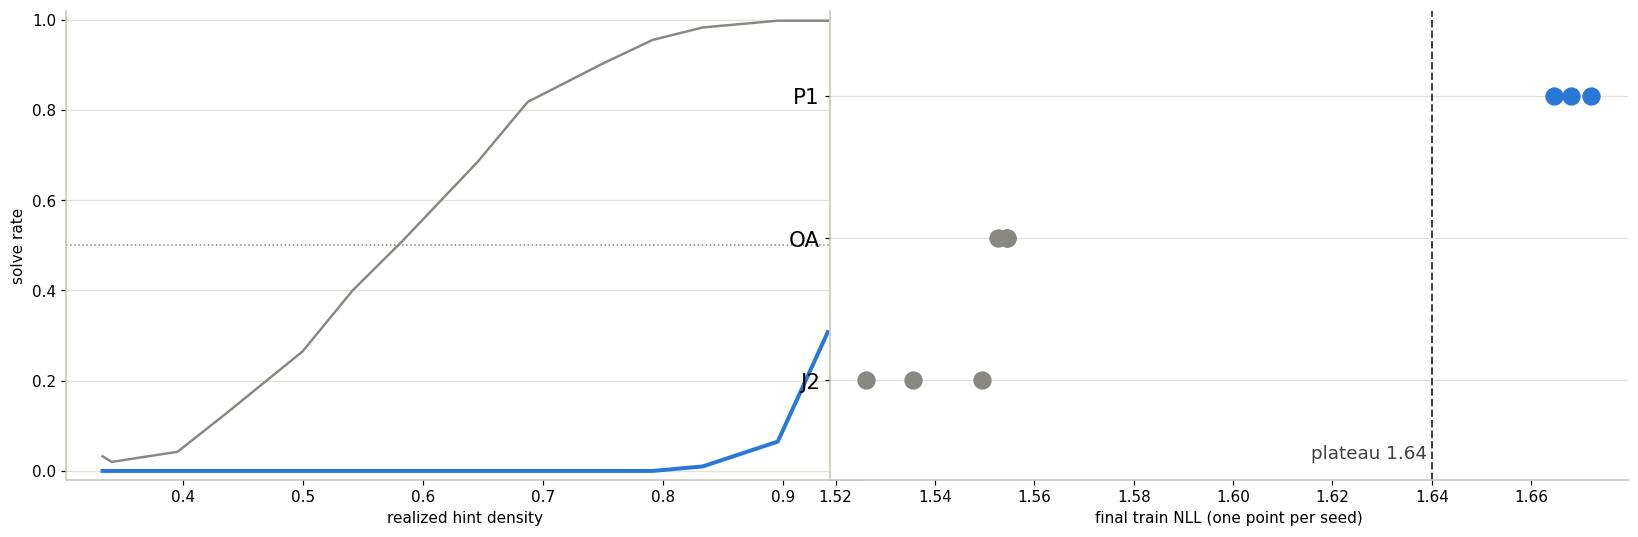

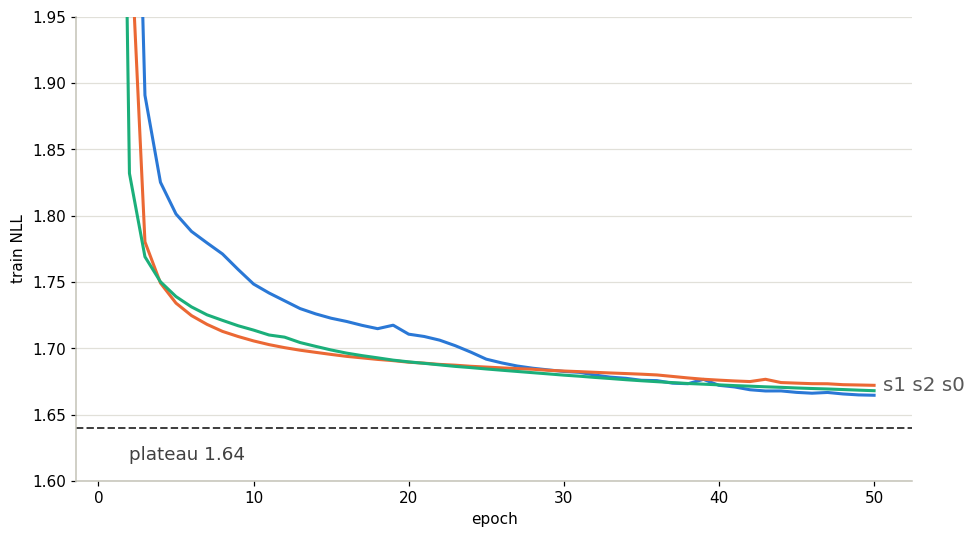

In [7]:
from notebooks.make_stageop_deck import draw_plateau, draw_tied_vs_untied, draw_trajectory

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
draw_tied_vs_untied(axes[0], S["curves"])
draw_plateau(axes[1], S["esc"])
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
draw_trajectory(ax, S["ms"])
fig.tight_layout()
plt.show()

for tag in ("P1", "OA", "J2"):
    n, nll = S["esc"][tag]
    print("  %-3s escapes %d/3   final train NLL %s"
          % (tag, n, "/".join("%.4f" % v for v in nll)))

## 7. What P1's censor does and does not separate, named in advance

**270,010 is below H1's 879,418** — `no_mlp L=12 d128`, the only attention-only
rung that has ever censored (1 of 3 crossing). So two different stories predict
exactly what was seen:

* *tying costs the deduction* — one block cannot serve sixteen roles; and
* *270k is simply too few parameters*, tied or not.

`P1` (the hypothesis, not the cell) says so itself, and it said so **before any
number landed**. The discriminating follow-up was registered at the same time
and is **running now as stage S**: hold the sharing fixed and buy the capacity
back with one knob, `d_model`. H1's floor **straddles** the two new widths —
that straddle is the only reason the stage has a cell that can separate the two
stories, so `scripts/_tiedwidth_dry_check.py` asserts it rather than describing
it, and the array depends `afterok` on that check.

In [8]:
from scripts.stagep_score import CENSOR_FLOOR, FOLLOWUP
p1 = S["got"]["P1"]["trainable"]
print("  P1  tied T=16 d192  %9s   below H1's floor" % "{:,}".format(p1))
print("  S1  tied T=16 d320  %9s   %s" % ("{:,}".format(FOLLOWUP["d320"]),
      "below H1's floor" if FOLLOWUP["d320"] < CENSOR_FLOOR else "ABOVE"))
print("  S2  tied T=16 d448  %9s   %s" % ("{:,}".format(FOLLOWUP["d448"]),
      "below H1's floor" if FOLLOWUP["d448"] < CENSOR_FLOOR else "ABOVE H1's floor"))
print()
print("  H1's censoring floor %s straddles the two new widths: %s"
      % ("{:,}".format(CENSOR_FLOOR),
         FOLLOWUP["d320"] < CENSOR_FLOOR < FOLLOWUP["d448"]))
assert FOLLOWUP["d320"] < CENSOR_FLOOR < FOLLOWUP["d448"]

  P1  tied T=16 d192    270,010   below H1's floor
  S1  tied T=16 d320    613,818   below H1's floor
  S2  tied T=16 d448  1,088,698   ABOVE H1's floor

  H1's censoring floor 879,418 straddles the two new widths: True


## 8. Accuracy first, and out-of-sample sufficiency

Validation token accuracy is read **before** `rho_50` on every stage, because it
never censors: P1 has no level, but it has an accuracy, and that accuracy orders
it against the twin it was built to replace.

The second figure is the registered sufficiency check (O4b / P3b). It asks
whether each cell sits on the N=48 **accuracy-to-solve** curve fitted over the
reference ladder, within the leave-one-out bar **0.0423**. A cell OFF that curve
would be the headline over everything above — it would mean tying (or the width
step) changed the *relation* between accuracy and solve rate rather than the
level on it.

**It returns nothing either way here, and that is printed below rather than
glossed.** Every one of the six seeds is grey, i.e. **not discriminating**:
`acc_vs_solve.py:227` requires both a tight bracket and a prediction off the
0.10 floor, and a residual failing either constrains nothing. So this check
neither supports nor refutes a change in the relation for OA or P1 — and P1
seed 0's `+0.0729`, the one residual outside the bar, is **also** non-
discriminating, so it is not evidence of a change either.

  J2  val token acc 0.4940 / 0.4949 / 0.4864   median 0.4940
  OA  val token acc 0.4862 / 0.4854 / 0.4853   median 0.4854
  P1  val token acc 0.4715 / 0.4561 / 0.4567   median 0.4567
  tied - untied at the same shape: -0.0372

  OA s0  acc 0.4862  predicted 0.3403  residual +0.0017  not discriminating
  OA s1  acc 0.4854  predicted 0.3176  residual +0.0013  not discriminating
  OA s2  acc 0.4853  predicted 0.3156  residual +0.0163  not discriminating
  P1 s0  acc 0.4715  predicted 0.1298  residual +0.0729  not discriminating
  P1 s1  acc 0.4561  predicted 0.0303  residual -0.0036  not discriminating
  P1 s2  acc 0.4567  predicted 0.0304  residual -0.0052  not discriminating

  0 of 6 seeds discriminating; worst |residual| among them none to take  (bar 0.0423)
  -> the curve cannot judge these cells; the check returns nothing,
     which is reported as nothing and not as agreement.


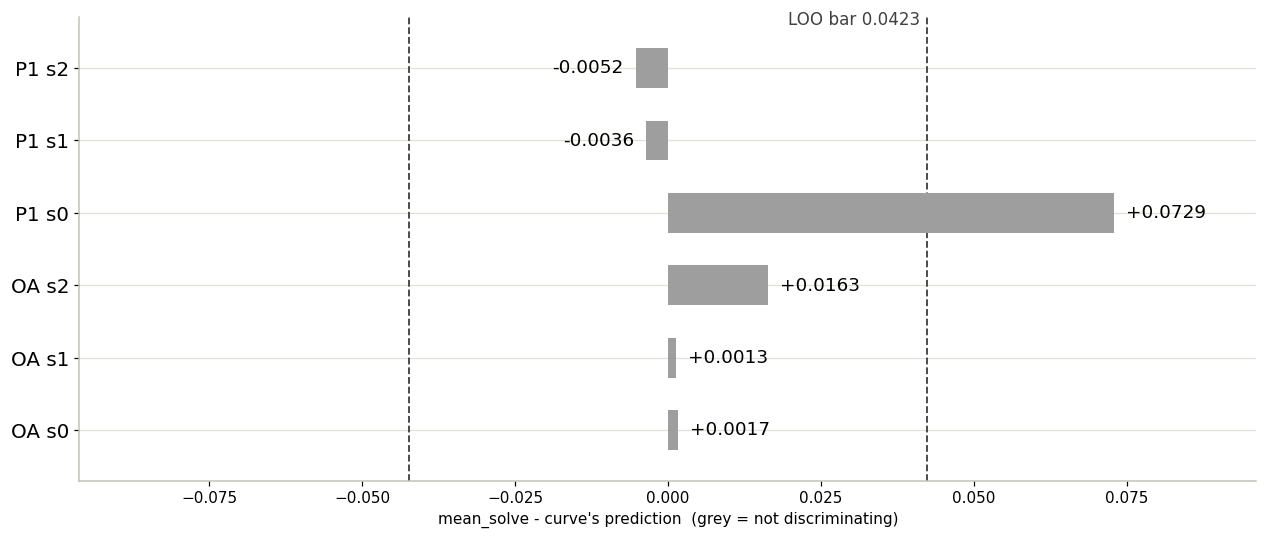

In [9]:
from notebooks.make_stageop_deck import draw_residuals, residuals
from scripts.stagej_score import LOO_BAR
from statistics import median

for tag in ("J2", "OA", "P1"):
    accs = [a for _s, a in S["acc"][tag]]
    print("  %-3s val token acc %s   median %.4f"
          % (tag, " / ".join("%.4f" % a for a in accs), median(accs)))
print("  tied - untied at the same shape: %+.4f"
      % (median([a for _s, a in S["acc"]["P1"]])
         - median([a for _s, a in S["acc"]["J2"]])))
print()

res = residuals(S["cells"], ("OA", "P1"))
fig, ax = plt.subplots(figsize=(11, 5))
draw_residuals(ax, res)
fig.tight_layout()
plt.show()

disc = [r for r in res if not r["weak"] and not r["oor"]]
for r in res:
    print("  %s s%d  acc %.4f  predicted %.4f  residual %+.4f  %s"
          % (r["tag"], r["seed"], r["acc"], r["pred"], r["resid"],
             "discriminating" if r in disc else "not discriminating"))
print()
print("  %d of %d seeds discriminating; worst |residual| among them %s  (bar %.4f)"
      % (len(disc), len(res),
         ("%.4f" % max(abs(r["resid"]) for r in disc)) if disc else "none to take",
         LOO_BAR))
if not disc:
    print("  -> the curve cannot judge these cells; the check returns nothing,")
    print("     which is reported as nothing and not as agreement.")

## 9. Against the previous best, on the same eval

The standing rule for replacing the minimum is unchanged: **every** seed crosses
0.5 **and** the median `rho_50` is at or below 0.740, on the same 14-point grid
to a floor of 0.33 at 400 instances per bin, with the seed spread quoted.

| quantity | previous best **J2** | stage O **OA** | stage P **P1** |
|---|---|---|---|
| trainable | 2,504,890 | 2,115,930 | 270,010 |
| `rho_50` | **0.580** | 0.741 | **CENSORED** |
| seeds crossing | 3/3 | 3/3 | 1/3 |
| plateau escapes | 3/3 | 3/3 | **0/3** |
| val token acc | 0.4940 | 0.4854 | 0.4567 |

**Before and after on the same pooled `s*` eval: 0.580 at 2,504,890 → 0.580 at
2,504,890, UNCHANGED.** Neither stage produced a replacement, and that is
reported with the numbers rather than asserted.

In [10]:
from scripts.stageo_score import STANDING_TRAINABLE
j2, oa, p1 = S["got"]["J2"], S["got"]["OA"], S["got"]["P1"]
assert j2["trainable"] == STANDING_TRAINABLE
# Formatted, not ==: STANDING_RHO50 is the literal 0.580 and j2["rho50"] is a
# median of grid-resolved bin edges, so exact float equality fails on a cell
# that is in fact the standing minimum. Three decimals is the resolution every
# rho_50 in the programme is quoted at.
assert "%.3f" % j2["rho50"] == "%.3f" % STANDING_RHO50, j2["rho50"]
assert j2["rho50_readable"]
assert not (oa["n_cross"] == 3 and oa["rho50"] <= FREE), \
    "OA would qualify under the standing rule -- the minimum WOULD move"
assert not p1["rho50_readable"], "P1 has a level; the censor claim is wrong"
print("  standing minimum BEFORE: rho_50 %.3f at %s trainable"
      % (STANDING_RHO50, "{:,}".format(STANDING_TRAINABLE)))
print("  standing minimum AFTER : rho_50 %.3f at %s trainable  (UNCHANGED)"
      % (STANDING_RHO50, "{:,}".format(STANDING_TRAINABLE)))

  standing minimum BEFORE: rho_50 0.580 at 2,504,890 trainable
  standing minimum AFTER : rho_50 0.580 at 2,504,890 trainable  (UNCHANGED)


## 10. What is established, what is not, and what runs next

**Established.**

* **OA `no_mlp L=16 d176`, 2,115,930 trainable, `rho_50` 0.741** (0.734/0.745/
  0.741), 3/3 crossing, 3/3 escaping the plateau, val acc 0.4854. A real measured
  level, `+0.001` past the free line = under `0.01 s*`, against a seed span of
  0.011. **O1 HELD**: no rung takes the minimum, and the transition stays
  bracketed by H2 (past) and J2 (free) — now with one measured point inside.
* **P1 `tied_no_mlp T=16 d192`, 270,010 trainable: `rho_50` CENSORED**, 1/3
  crossing, **0/3 escaping the 1.64 plateau** (1.6646/1.6721/1.6681), val acc
  0.4567 against the twin's 0.4940. **P2 FALSIFIED**, which by registration
  outranks P0.
**Checked and inconclusive**, which is not the same as established: the
accuracy-to-solve sufficiency check (O4b / P3b) returns **no discriminating
seed at all** for either cell — all six fail the tight-bracket-and-off-floor
test — so it says nothing about whether the width step or the tying changed the
accuracy-to-solve *relation*. P1 seed 0's `+0.0729` sits outside the 0.0423 bar
and is non-discriminating too.

**Not established, and registered as such.**

* **O0 — size or shape.** Unanswerable as registered: it needed two arms at
  matched size and OB was cancelled mid-flight. Not called.
* **P0 — iteration or pipeline.** The censor is a *bound* against an
  optimization-limited cell, and P2's falsification outranks it. Stage P
  produced **no architecture result**, and saying otherwise would be reading a
  recipe failure as a structural one.
* **Whether tying can do direct deduction at all.** P1 names the confound:
  270,010 is below H1's 879,418 censoring floor, so "tying costs it" and "270k
  is too few" are not separated by this stage and were never claimed to be.

**What runs next.** **Stage S, array `51853969`, running now** — the registered
follow-up: hold the sharing fixed and buy the capacity back at `d320` (613,818,
below H1's floor, a trend point) and `d448` (1,088,698, **above** it, the
discriminating cell), 3 seeds each, one knob. If the plateau floor moves with
width and d448 escapes 1.64, the floor was capacity and a tied cell can be read
as an architecture; if all three widths sit inside 0.01 of each other, the floor
belongs to the tied **object** and the honest statement becomes "tying cannot be
*trained* to do DD here", not "tying cannot do DD".

**And the fallback is already named**, so it cannot be chosen after the fact: if
stage S falsifies the tied route with the plateau escaped, that is a clean
negative and the analyzability route shifts to the **shallow untied hub** —
`full L=6 d256`, 4,899,898 trainable, `rho_50` 0.592, six composed layers, the
most tractable free cell known.